#**I) Índices Econômicos e de Mercado:**

#**1) Lista de Sites para pesquisar Indices Econômicos e de Mercado**

Vamos criar uma lista de links para consultar os principais indices de Mercado:

> CDI - Certificado de Depósito Interbancário
https://www.bcb.gov.br/htms/SELIC/SELICdiarios.asp?frame=1

> Taxa SELIC - Taxa básica de juros da economia
https://www.bcb.gov.br/

> IPCA - Índice de preços ao consumidor
https://www.bcb.gov.br/

> IFIX e IBOVESPA (B3)
https://www.b3.com.br/pt_br/market-data-e-indices/servicos-de-dados/market-data/cotacoes/indices.htm

> IFIX
https://br.investing.com/indices/bm-fbovespa-real-estate-ifix

> IBOVESPA
https://br.investing.com/indices/bovespa

> S&P500 (SPX)
https://br.investing.com/indices/us-spx-500

> Nasdaq (IXIC)
https://br.investing.com/indices/nasdaq-composite

> Nasdaq-100 (NDX)
https://br.investing.com/indices/nq-100


**Outros Links Interessantes:**
> BC - Calculadora CDI, SELIC, etc
https://www3.bcb.gov.br/CALCIDADAO/publico/exibirFormCorrecaoValores.do?method=exibirFormCorrecaoValores&aba=5

> BC - Estatísticas
https://www.bcb.gov.br/estatisticas

> BC - Histórico de Taxas de Juros
https://www.bcb.gov.br/controleinflacao/historicotaxasjuros

> Bolsa B3
https://www.b3.com.br/pt_br/para-voce

In [ ]:
#@title 2) Inserindo e Exibindo Indices Econômicos e Indices de Mercado (Manual)

# Inicio: Inserindo a data de coleta dos Indices
from datetime import datetime

def coletar_data_usuario():
    while True:
        data_entrada = input("Digite a data no formato DD/MM/AAAA: ")
        try:
            data_convertida = datetime.strptime(data_entrada, '%d/%m/%Y')
            return data_convertida
        except ValueError:
            print("Formato de data inválido. Por favor, tente novamente.")

data_usuario = coletar_data_usuario()
# Fim: Inserindo a data de coleta dos Indices


def coletar_indices_economicos():
    indices_economicos = {}
    indices_economicos['CDI'] = float(input("Digite o valor do CDI: "))
    indices_economicos['SELIC'] = float(input("Digite o valor da taxa SELIC: "))
    indices_economicos['IPCA'] = float(input("Digite o valor do IPCA: "))
    return indices_economicos

def coletar_indices_mercado():
    indices_mercado = {}
    indices_mercado['IFIX'] = float(input("Digite o valor do IFIX: "))
    indices_mercado['Ibovespa'] = float(input("Digite o valor do Ibovespa: "))
    indices_mercado['S&P 500'] = float(input("Digite o valor do S&P 500: "))
    indices_mercado['Nasdaq'] = float(input("Digite o valor do Nasdaq Composite: "))
    indices_mercado['Nasdaq-100'] = float(input("Digite o valor do Nasdaq-100: "))
    return indices_mercado

def main():
    indices_economicos = coletar_indices_economicos()
    indices_mercado = coletar_indices_mercado()

    print("\nData de Coleta dos Indices:", data_usuario.strftime('%d/%m/%Y'))

    print("\nÍndices Econômicos Coletados:")
    for indice, valor in indices_economicos.items():
        print(f"{indice}: {valor}")

    print("\nÍndices de Mercado Coletados:")
    for indice, valor in indices_mercado.items():
        print(f"{indice}: {valor}")

if __name__ == "__main__":
    main()


Digite a data no formato DD/MM/AAAA: 23/04/2024
Digite o valor do CDI: 10.65
Digite o valor da taxa SELIC: 10.75
Digite o valor do IPCA: 3.93
Digite o valor do IFIX: 3373.24
Digite o valor do Ibovespa: 125148.07
Digite o valor do S&P 500: 5070.55
Digite o valor do Nasdaq Composite: 15696.64
Digite o valor do Nasdaq-100: 17471.47

Data de Coleta dos Indices: 23/04/2024

Índices Econômicos Coletados:
CDI: 10.65
SELIC: 10.75
IPCA: 3.93

Índices de Mercado Coletados:
IFIX: 3373.24
Ibovespa: 125148.07
S&P 500: 5070.55
Nasdaq: 15696.64
Nasdaq-100: 17471.47


In [2]:
#@title 3) Instalando módulos para um dashboard dos Indices

!pip install pandas
!pip install dash
!pip install panel

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 31.0 MB/s eta 0:00:00


In [4]:
#@title 4) Montando um DashBoard com os Indices (V1 - Dados coletados anteriormente) - Biblioteca Panel

##
indices_economicos = {
    "PIB": 7.5,  # exemplo de valor para o PIB
    "Inflação": 3.2,  # exemplo de valor para a Inflação
    "Taxa de Desemprego": 5.4,  # exemplo de valor para a Taxa de Desemprego
    "Balança Comercial": 10.0  # exemplo de valor para a Balança Comercial
}

indices_mercado = {
    "Ibovespa": 120000,  # exemplo de valor para o Ibovespa
    "NASDAQ": 14000,  # exemplo de valor para o NASDAQ
    "Dow Jones": 34000,  # exemplo de valor para o Dow Jones
    "S&P 500": 4300  # exemplo de valor para o S&P 500
}

##

import panel as pn

# Configurar o Panel para funcionar no modo notebook
pn.extension()

# Função para criar o painel com base na escolha do usuário
def criar_painel(escolha):
    if escolha == 'Índices Econômicos':
        paineis = [pn.pane.Markdown(f"**{indice}:** {valor}") for indice, valor in indices_economicos.items()]
        titulo = "# Índices Econômicos"
    else:
        paineis = [pn.pane.Markdown(f"**{indice}:** {valor}") for indice, valor in indices_mercado.items()]
        titulo = "# Índices de Mercado"
    return pn.Column(pn.pane.Markdown(titulo), *paineis)

# Criar um widget de seleção para o usuário escolher o tipo de índice
seletor_indices = pn.widgets.RadioButtonGroup(
    name='Seletor de Índices', options=['Índices Econômicos', 'Índices de Mercado'], button_type='success'
)

# Painel dinâmico que será atualizado com base na seleção
painel_dinamico = pn.bind(criar_painel, seletor_indices)

# Criar um layout para o dashboard
dashboard = pn.Column(seletor_indices, painel_dinamico)

# Tornar o dashboard 'servable' para visualização
dashboard.servable()



Column
    [0] RadioButtonGroup(button_type='success', name='Seletor de Índices', options=['Índices Econômicos', ...], value='Índices Econômicos')
    [1] ParamFunction(function, _pane=Column, defer_load=False)

In [5]:
#@title 5) Montando um DashBoard Gráfico com os Indices (V2 - Dados Estaticos no código) - Biblioteca Dash

import dash
from dash import dcc, html
import pandas as pd

#@title 5) Montando um DashBoard Gráfico com os Indices (V2 - Dados Estaticos no código) - Biblioteca Dash

import dash
from dash import dcc, html  # Atualizado
import pandas as pd

# Simulando dados coletados
indices_economicos = {'CDI': 12.15, 'SELIC': 12.25, 'IPCA': 4.82}
indices_mercado = {'IFIX': 3180.24, 'Ibovespa': 120410, 'S&P 500': 4411.55, 'Nasdaq': 13767.74, 'Nasdaq-100': 15482.79}

# Convertendo para DataFrame
df_economicos = pd.DataFrame(list(indices_economicos.items()), columns=['Índice', 'Valor'])
df_mercado = pd.DataFrame(list(indices_mercado.items()), columns=['Índice', 'Valor'])

# Iniciando o aplicativo Dash
app = dash.Dash(__name__)

app.layout = html.Div(children=[
    html.H1(children='Dashboard de Índices Econômicos e de Mercado'),

    html.Div(children=[
        html.H2(children='Índices Econômicos'),
        dcc.Graph(
            id='economicos-graph',
            figure={
                'data': [{'x': df_economicos['Índice'], 'y': df_economicos['Valor'], 'type': 'bar'}],
                'layout': {'title': 'Índices Econômicos'}
            }
        )
    ]),

    html.Div(children=[
        html.H2(children='Índices de Mercado'),
        dcc.Graph(
            id='mercado-graph',
            figure={
                'data': [{'x': df_mercado['Índice'], 'y': df_mercado['Valor'], 'type': 'bar', 'marker': {'color': 'green'}}],
                'layout': {'title': 'Índices de Mercado'}
            }
        )
    ])
])

if __name__ == '__main__':
    app.run_server(debug=True)

<IPython.core.display.Javascript object>

#**II) Renda Fixa - Beta 1**

Para ajudar a escolher o melhor ativo de renda fixa com base na taxa, tempo e tributação, podemos criar um programa Python simples que:

1) Solicite ao usuário para inserir as informações de vários ativos, incluindo taxa de juros, prazo de maturidade e alíquota de imposto aplicável.

2) Calcule o rendimento líquido após impostos para cada ativo.

3) Liste todos os ativos que o usuário inseriu

4) Compare os rendimentos líquidos e recomende o ativo com o maior retorno ajustado ao risco e tempo.

In [ ]:
#@title 1) Renda Fixa - Escolha de um Melhor Ativo de Renda Fixa
# Baseado na Taxa, Tempo Investido e Aliquota de IR

# Título na saída de terminal Google Colab com Formatação Código ANSI para Negrito
print("\033[1m" + "Coleta de Ativos de Renda Fixa (Cenários):" + "\033[0m")
print()

# Função para Calcular o Rendimento Liquido
def calcular_rendimento_liquido(valor_investido, taxa_juros, prazo, aliquota_imposto):
    rendimento_bruto = valor_investido * (1 + (taxa_juros * prazo))
    imposto = (rendimento_bruto - valor_investido) * aliquota_imposto
    rendimento_liquido = rendimento_bruto - imposto
    return rendimento_liquido

# Função para Coletar os dados dos Ativos de Renda Fixa
def coletar_dados_ativos():
    ativos = []
    while True:
        valor_investido = float(input("Valor a ser investido no ativo: "))
        taxa_juros = float(input("Taxa de juros anual do ativo (em decimal, ex: 10% = 0.10): "))
        prazo = float(input("Prazo de investimento em anos: "))
        aliquota_imposto = float(input("Alíquota de imposto sobre o rendimento (em decimal): "))
        ativos.append((valor_investido, taxa_juros, prazo, aliquota_imposto))
        continuar = input("Deseja adicionar outro ativo? (s/n): ")
        if continuar.lower() != 's':
            break
    return ativos

# Função para Exibir os dados dos Ativos de Renda Fixa
def exibir_detalhes_ativos(ativos):
    print()
    print("\033[1m" + "Lista de Ativos de Renda Fixa (Cenários) e seus Rendimentos:" + "\033[0m")
    for i, ativo in enumerate(ativos, start=1):
        rendimento = calcular_rendimento_liquido(*ativo)
        print(f"Ativo {i}: Valor Investido: {ativo[0]}, Taxa de Juros: {ativo[1]*100}%, Prazo: {ativo[2]} anos, Alíquota de Imposto: {ativo[3]*100}%, Rendimento Líquido: {rendimento}")

# Função para Recomendar o melhor Ativo de Renda Fixa
def recomendar_melhor_ativo(ativos):
    melhor_rendimento = 0
    melhor_ativo = None
    for ativo in ativos:
        rendimento = calcular_rendimento_liquido(*ativo)
        if rendimento > melhor_rendimento:
            melhor_rendimento = rendimento
            melhor_ativo = ativo
    return melhor_ativo, melhor_rendimento

ativos = coletar_dados_ativos()
exibir_detalhes_ativos(ativos)
melhor_ativo, melhor_rendimento = recomendar_melhor_ativo(ativos)
print()
print("\033[1m" + "Melhor Ativo:" + "\033[0m")
print(f"O melhor ativo para investimento é aquele com taxa de juros {melhor_ativo[1]*100}%, prazo de {melhor_ativo[2]} anos e alíquota de imposto {melhor_ativo[3]*100}%. Rendimento líquido após impostos: {melhor_rendimento}")


Coleta de Ativos de Renda Fixa (Cenários):

Valor a ser investido no ativo: 1000
Taxa de juros anual do ativo (em decimal): .12
Prazo de investimento em anos: 10
Alíquota de imposto sobre o rendimento (em decimal): .15
Deseja adicionar outro ativo? (s/n): s
Valor a ser investido no ativo: 1000
Taxa de juros anual do ativo (em decimal): .12
Prazo de investimento em anos: 1
Alíquota de imposto sobre o rendimento (em decimal): .2
Deseja adicionar outro ativo? (s/n): n

Lista de Ativos de Renda Fixa (Cenários) e seus Rendimentos:
Ativo 1: Valor Investido: 1000.0, Taxa de Juros: 12.0%, Prazo: 10.0 anos, Alíquota de Imposto: 15.0%, Rendimento Líquido: 2020.0
Ativo 2: Valor Investido: 1000.0, Taxa de Juros: 12.0%, Prazo: 1.0 anos, Alíquota de Imposto: 20.0%, Rendimento Líquido: 1096.0

Melhor Ativo:
O melhor ativo para investimento é aquele com taxa de juros 12.0%, prazo de 10.0 anos e alíquota de imposto 15.0%. Rendimento líquido após impostos: 2020.0


In [ ]:
#@title 2) Renda Fixa - Calculando rentabilidade de um CDB

# Baseado nas fórmulas de Juros Compostos, conversão de Juros Ano para Mês e tabela de Aliquotas
# Cálculo de Rentabilidade de um CDB

import pandas as pd

def calcular_rentabilidade_cdb(tempo_meses, taxa_anual, capital_inicial, tabela_ir):

    print("\033[1m" + "Cálculos efetuados:" + "\033[0m")

    # Converter taxa anual para mensal
    taxa_mensal = (1 + taxa_anual)**(1/12) - 1
    print(f"Taxa anual: {taxa_anual*100:.2f}%")
    print(f"Taxa mensal: {taxa_mensal*100:.2f}%")

    # Calcular o valor final bruto diretamente com o tempo em meses
    valor_final_bruto = capital_inicial * (1 + taxa_mensal)**tempo_meses
    print(f"Valor final bruto: R$ {valor_final_bruto:.2f}")

    # Determinar a alíquota de IR com base no tempo em meses
    if tempo_meses <= 6:
        aliquota_ir = tabela_ir.loc[tabela_ir['Período de Aplicação'] == 'Até 180 dias', 'Alíquota IR'].iloc[0]
    elif tempo_meses <= 12:
        aliquota_ir = tabela_ir.loc[tabela_ir['Período de Aplicação'] == 'De 181 a 360 dias', 'Alíquota IR'].iloc[0]
    elif tempo_meses <= 24:
        aliquota_ir = tabela_ir.loc[tabela_ir['Período de Aplicação'] == 'De 361 a 720 dias', 'Alíquota IR'].iloc[0]
    else:
        aliquota_ir = tabela_ir.loc[tabela_ir['Período de Aplicação'] == 'Acima de 720 dias', 'Alíquota IR'].iloc[0]
    print(f"Alíquota de IR aplicável: {aliquota_ir}%")

    # Calcular o IR sobre o rendimento
    rendimento_bruto = valor_final_bruto - capital_inicial
    imposto_devido = rendimento_bruto * (aliquota_ir / 100)
    print(f"Imposto devido sobre o rendimento: R$ {imposto_devido:.2f}")

    # Calcular o valor final líquido
    valor_final_liquido = valor_final_bruto - imposto_devido

    return valor_final_liquido

# Criação da tabela de IR
tabela_ir = pd.DataFrame({
    "Período de Aplicação": ["Até 180 dias", "De 181 a 360 dias", "De 361 a 720 dias", "Acima de 720 dias"],
    "Alíquota IR": [22.5, 20, 17.5, 15]
})

# Solicitar os dados do usuário
print("\033[1m\033[4m" + "Cálculo de Rentabilidade de um CDB" + "\033[0m")
print()
print("\033[1m" + "Coleta de Dados pelo usuário:" + "\033[0m")
tempo_meses = float(input("Informe o tempo do investimento em meses (M): "))
taxa_anual = float(input("Informe a taxa de juros anual (em forma decimal, ex: 10% = 0.10): "))
capital_inicial = float(input("Informe o capital inicial investido em Reais (R$): "))
print()

# Calcular a rentabilidade do CDB
valor_final_liquido = calcular_rentabilidade_cdb(tempo_meses, taxa_anual, capital_inicial, tabela_ir)

print(f"O valor final líquido após {tempo_meses} meses é: R$ {valor_final_liquido:.2f}")


Cálculo de Rentabilidade de um CDB

Coleta de Dados pelo usuário:
Informe o tempo do investimento em meses (M): 28
Informe a taxa de juros anual (em forma decimal, ex: 10% = 0.10): .1225
Informe o capital inicial investido em Reais (R$): 10000

Cálculos efetuados:
Taxa anual: 12.25%
Taxa mensal: 0.97%
Valor final bruto: R$ 13094.88
Alíquota de IR aplicável: 15.0%
Imposto devido sobre o rendimento: R$ 464.23
O valor final líquido após 28.0 meses é: R$ 12630.65


#**Melhorias a serem feitas neste código**

Perguntar ao usuario qual tipo de Ativo ele usará para o cálculo:

LCI/LCA - Isento de IR

CDB - Tabela regressiva de IR

Tesouro SELIC - Além da Tabela regressiva de IR considerar a taxa anual do Tesouro de 0.20/ano dividida em 2 cobranças de 0.10

#**III) Renda Variável**

A ideia é trabalhar com a fórmula do número mágico de Graham.(Benjamin Graham)

É usada para calcular o preço justo de uma ação (FPJG) e é conhecida como a fórmula do número mágico de Graham ou, às vezes, como a fórmula de valorização de Graham.

FPJG = Raiz Quadrada(22.5 x LPA x VPA)

Esta fórmula é usada para estimar o valor intrínseco de uma ação com base em fundamentos financeiros. A ideia é que, se o preço da ação está abaixo do valor calculado pela fórmula de Graham, a ação pode estar subvalorizada e, portanto, ser uma boa compra segundo os princípios do investimento em valor. Da mesma forma, se estiver acima, pode estar sobrevalorizada.

A raiz quadrada é usada na fórmula para trazer o produto dos múltiplos de P/E e P/BV de volta para um nível de preço de ação similar. É uma maneira de normalizar o valor que de outra forma poderia ser muito grande devido à multiplicação de dois termos.





In [ ]:
#@title 1) Montando o Google Drive no ambiente do Google Colab

print("Montando o Google Drive no ambiente do Google Colab")
from google.colab import drive
drive.mount('/content/gdrive')

Montando o Google Drive no ambiente do Google Colab
Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
#@title 2) Fazendo a leitura da aba de uma planilha para o Pandas

import pandas as pd

# Substitua 'caminho_para_o_arquivo.xlsx' pelo caminho real do seu arquivo Excel
caminho_do_arquivo = '/content/gdrive/MyDrive/Colab Notebooks/XPE_MBA_CDMF_Desafio_Final/Dados/02_Limpo/acoes_status_invest.xlsx'
nome_da_aba = 'acoes(calculo)'  # Substitua 'NomeDaAba' pelo nome real da aba que você deseja ler

# Usando o pandas para ler a aba especificada da planilha do Excel
df = pd.read_excel(caminho_do_arquivo, sheet_name=nome_da_aba)

# Exibindo as primeiras linhas do DataFrame para verificar se foi carregado corretamente
print(df.head())

# Exibindo as colunas para ver se não tem espaço em branco nos nomes
print()
print(df.columns)

# Remover espaços extras dos nomes das colunas (Se tiver e não tiver sido corrigido no excel direto)
df.columns = df.columns.str.strip()
# OBS: Isto foi feito pois uma coluna estava com espaço em branco no nome e na hora de fazer um cálculo deu erro

  TICKER  PRECO     DY    P/L  P/VP  LIQ CORRENTE     ROE    ROA    ROIC  \
0  AALR3  10.40    NaN  -4.67  1.21          74.0 -2592.0  -9.58   -51.0   
1  ABCB4  20.92   5.76   5.99  0.83         381.0  1374.0   1.41     NaN   
2  ABEV3  13.35   5.71  13.95  2.33         111.0  1671.0  10.94  1863.0   
3  AESB3  10.27    NaN  39.18  1.38         111.0   353.0   0.80   504.0   
4  AGRO3  24.11  13.32   9.65  1.13         214.0  1168.0   7.31   759.0   

   LIQUIDEZ MEDIA DIARIA    VPA   LPA  VALOR DE MERCADO  
0           1.103505e+06   8.58 -2.22      1.230245e+09  
1           1.103897e+07  25.31  3.49      4.729805e+09  
2           3.144968e+08   5.73  0.96      2.103137e+11  
3           2.423920e+07   7.43  0.26      6.181793e+09  
4           1.976675e+07  21.40  2.50      2.475698e+09  

Index(['TICKER', 'PRECO', 'DY', 'P/L', 'P/VP', 'LIQ CORRENTE', 'ROE', 'ROA',
       'ROIC', 'LIQUIDEZ MEDIA DIARIA', 'VPA', 'LPA', 'VALOR DE MERCADO'],
      dtype='object')


In [ ]:
#@title 3) Criando uma coluna nova com a FPJG

# Para calcular o preço justo de Graham para cada ação listada na planilha, precisamos seguir a fórmula:
# Preço Justo de Graham (FPJG) = Raiz Quadrada de (22.5 * LPA * VPA)

# Vamos assumir que o DataFrame 'df' já foi carregado corretamente com a aba 'acoes(calculo)'.

import numpy as np

# # Carregar a planilha em um DataFrame
# # Substitua 'caminho_da_planilha.xlsx' pelo caminho da sua planilha
# df = pd.read_excel('caminho_da_planilha.xlsx')

# Calcular a coluna FPJG
df['FPJG'] = np.sqrt(22.5 * df['VPA'] * df['LPA'])

# Arredondar a coluna 'FPJG' para duas casas decimais
df['FPJG'] = df['FPJG'].round(2)

# Mostrar o DataFrame atualizado com Display para usar o recurso de Tabela Interativa (Similar visualização Excel)
display(df)

/usr/local/lib/python3.10/dist-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


,TICKER,PRECO,DY,P/L,P/VP,LIQ CORRENTE,ROE,ROA,ROIC,LIQUIDEZ MEDIA DIARIA,VPA,LPA,VALOR DE MERCADO,FPJG
0,AALR3,10.40,NaN,-4.67,1.21,74.0,-2592.0,-9.58,-51.0,1.103505e+06,8.58,-2.22,1.230245e+09,NaN
1,ABCB4,20.92,5.76,5.99,0.83,381.0,1374.0,1.41,NaN,1.103897e+07,25.31,3.49,4.729805e+09,44.58
2,ABEV3,13.35,5.71,13.95,2.33,111.0,1671.0,10.94,1863.0,3.144968e+08,5.73,0.96,2.103137e+11,11.13
3,AESB3,10.27,NaN,39.18,1.38,111.0,353.0,0.80,504.0,2.423920e+07,7.43,0.26,6.181793e+09,6.59
4,AGRO3,24.11,13.32,9.65,1.13,214.0,1168.0,7.31,759.0,1.976675e+07,21.40,2.50,2.475698e+09,34.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
341,WHRL4,4.16,4.95,17.77,2.62,108.0,1473.0,4.02,1766.0,4.314493e+04,1.59,0.23,6.220729e+09,2.87
342,WIZC3,5.56,8.01,8.47,2.14,84.0,2532.0,4.42,2169.0,2.292743e+06,2.59,0.66,8.890845e+08,6.20
343,WLMM4,31.55,2.30,10.13,1.76,248.0,1735.0,12.01,1380.0,1.067122e+05,17.94,3.11,1.056913e+09,35.43
344,YDUQ3,19.78,NaN,55.49,1.95,156.0,351.0,1.13,882.0,9.827928e+07,10.16,0.36,6.113777e+09,9.07


In [ ]:
#@title 4) Exibindo quantos registros possuem a nova coluna FPJG com erro (NaN)
# Este erro ocorre quando uma das colunas da fórmula (VPA ou LPA) tem valor negativo
# Neste caso não é possível avaliar o preço justo através deste método

# a) Contar o número de registros com 'FPJG' como NaN
num_nan = df['FPJG'].isna().sum()

# Exibir o número
print(f"Número de registros com FPJG como NaN: {num_nan}")

# b) Filtrar o DataFrame para exibir apenas linhas onde 'FPJG' é NaN
df_nan = df[df['FPJG'].isna()]

# Exibir essas linhas
print("\nExibindo tabela interatica com Display - Clicar no 1º Botão Azul para converter")
display(df_nan)


Número de registros com FPJG como NaN: 75

Exibindo tabela interatica com Display - Clicar no 1º Botão Azul para converter


,TICKER,PRECO,DY,P/L,P/VP,LIQ CORRENTE,ROE,ROA,ROIC,LIQUIDEZ MEDIA DIARIA,VPA,LPA,VALOR DE MERCADO,FPJG
0,AALR3,10.40,NaN,-4.67,1.21,74.0,-2592.0,-9.58,-51.0,1103504.61,8.58,-2.22,1.230245e+09,NaN
5,AGXY3,3.97,1.00,-3.45,0.64,108.0,-1862.0,-2.24,1329.0,202240.07,6.18,-1.15,6.781752e+08,NaN
8,ALPA3,9.34,NaN,-22.66,1.18,351.0,-522.0,-3.56,-800.0,36514.64,7.89,-0.41,6.348882e+09,NaN
9,ALPA4,9.25,NaN,-22.44,1.17,351.0,-522.0,-3.56,-800.0,43740842.00,7.89,-0.41,6.348882e+09,NaN
10,ALPK3,4.20,NaN,-8.32,2.37,55.0,-2846.0,-4.21,728.0,663386.04,1.77,-0.51,9.005914e+08,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
325,USIM5,6.81,4.83,-23.53,0.36,343.0,-155.0,-0.90,-206.0,74909783.39,18.71,-0.29,8.526416e+09,NaN
331,VIVR3,3.42,NaN,-1.27,4.39,109.0,-34616.0,-19.63,-12926.0,773378.36,0.78,-2.70,8.097378e+07,NaN
337,VVAR4,95.68,NaN,-127.20,51.29,74.0,-4032.0,-5.54,-1142.0,NaN,1.87,-0.75,1.236082e+09,NaN
340,WEST3,1.51,NaN,-2.87,0.58,316.0,-2029.0,-14.88,-2586.0,370679.93,2.59,-0.53,1.671217e+08,NaN


In [ ]:
#@title 5) Limpando o DF com estes erros e exibindo apenas os registros que fazem sentido esta analise de preço justo com este método

# a) Remover linhas onde 'FPJG' é NaN
df = df.dropna(subset=['FPJG'])

# b) Exibir o número total de registros (linhas) no DataFrame
num_registros = df.shape[0]

# Exibir o número
print(f"Número total de registros no DataFrame: {num_registros}")

# c) Mostrar o DataFrame atualizado
print("\nExibindo tabela interatica com Display - Clicar no 1º Botão Azul para converter")
display(df)


Número total de registros no DataFrame: 271

Exibindo tabela interatica com Display - Clicar no 1º Botão Azul para converter


,TICKER,PRECO,DY,P/L,P/VP,LIQ CORRENTE,ROE,ROA,ROIC,LIQUIDEZ MEDIA DIARIA,VPA,LPA,VALOR DE MERCADO,FPJG
1,ABCB4,20.92,5.76,5.99,0.83,381.0,1374.0,1.41,NaN,1.103897e+07,25.31,3.49,4.729805e+09,44.58
2,ABEV3,13.35,5.71,13.95,2.33,111.0,1671.0,10.94,1863.0,3.144968e+08,5.73,0.96,2.103137e+11,11.13
3,AESB3,10.27,NaN,39.18,1.38,111.0,353.0,0.80,504.0,2.423920e+07,7.43,0.26,6.181793e+09,6.59
4,AGRO3,24.11,13.32,9.65,1.13,214.0,1168.0,7.31,759.0,1.976675e+07,21.40,2.50,2.475698e+09,34.70
6,ALLD3,6.30,5.62,7.72,0.38,173.0,404.0,1.81,744.0,1.677697e+05,16.66,0.82,5.872897e+08,17.53
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339,WEGE3,33.17,1.80,28.02,8.64,186.0,3082.0,16.52,2544.0,3.059085e+08,3.84,1.18,1.392250e+11,10.10
341,WHRL4,4.16,4.95,17.77,2.62,108.0,1473.0,4.02,1766.0,4.314493e+04,1.59,0.23,6.220729e+09,2.87
342,WIZC3,5.56,8.01,8.47,2.14,84.0,2532.0,4.42,2169.0,2.292743e+06,2.59,0.66,8.890845e+08,6.20
343,WLMM4,31.55,2.30,10.13,1.76,248.0,1735.0,12.01,1380.0,1.067122e+05,17.94,3.11,1.056913e+09,35.43


In [ ]:
#@title 6) Criando novas colunas para avaliar se o PRECO atual está Sobrevalorizado ou Subvalorizado

# Calcular a coluna 'PRECO/FPJG' como percentual
df['PRECO/FPJG(%)'] = (df['PRECO'] / df['FPJG']) * 100

# Arredondar para 0 casas decimais
df['PRECO/FPJG(%)'] = df['PRECO/FPJG(%)'].round(0)

# Criar a coluna 'STATUS FPJG'
df['STATUS FPJG'] = df['PRECO/FPJG(%)'].apply(lambda x: 'Sobrevalorizado' if x > 100 else 'Subvalorizado')

# Exibir o DataFrame atualizado
display(df)


,TICKER,PRECO,DY,P/L,P/VP,LIQ CORRENTE,ROE,ROA,ROIC,LIQUIDEZ MEDIA DIARIA,VPA,LPA,VALOR DE MERCADO,FPJG,PRECO/FPJG(%),STATUS FPJG
1,ABCB4,20.92,5.76,5.99,0.83,381.0,1374.0,1.41,NaN,1.103897e+07,25.31,3.49,4.729805e+09,44.58,47.0,Subvalorizado
2,ABEV3,13.35,5.71,13.95,2.33,111.0,1671.0,10.94,1863.0,3.144968e+08,5.73,0.96,2.103137e+11,11.13,120.0,Sobrevalorizado
3,AESB3,10.27,NaN,39.18,1.38,111.0,353.0,0.80,504.0,2.423920e+07,7.43,0.26,6.181793e+09,6.59,156.0,Sobrevalorizado
4,AGRO3,24.11,13.32,9.65,1.13,214.0,1168.0,7.31,759.0,1.976675e+07,21.40,2.50,2.475698e+09,34.70,69.0,Subvalorizado
6,ALLD3,6.30,5.62,7.72,0.38,173.0,404.0,1.81,744.0,1.677697e+05,16.66,0.82,5.872897e+08,17.53,36.0,Subvalorizado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339,WEGE3,33.17,1.80,28.02,8.64,186.0,3082.0,16.52,2544.0,3.059085e+08,3.84,1.18,1.392250e+11,10.10,328.0,Sobrevalorizado
341,WHRL4,4.16,4.95,17.77,2.62,108.0,1473.0,4.02,1766.0,4.314493e+04,1.59,0.23,6.220729e+09,2.87,145.0,Sobrevalorizado
342,WIZC3,5.56,8.01,8.47,2.14,84.0,2532.0,4.42,2169.0,2.292743e+06,2.59,0.66,8.890845e+08,6.20,90.0,Subvalorizado
343,WLMM4,31.55,2.30,10.13,1.76,248.0,1735.0,12.01,1380.0,1.067122e+05,17.94,3.11,1.056913e+09,35.43,89.0,Subvalorizado


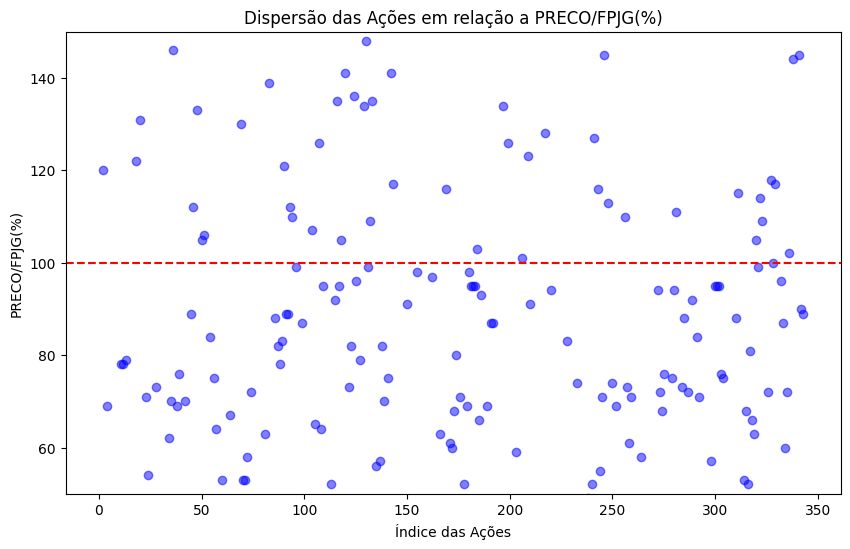

In [ ]:
#@title 7) Criando gráfico para ver Sobrevalorizados e Subvalorizados

import matplotlib.pyplot as plt

# Converter a coluna 'PRECO/FPJG(%)' de volta para float removendo o símbolo de porcentagem
df['PRECO/FPJG(%)_float'] = df['PRECO/FPJG(%)'].str.rstrip('%').astype('float')

# Criar o gráfico de dispersão
plt.figure(figsize=(10, 6))
plt.scatter(df.index, df['PRECO/FPJG(%)_float'], color='blue', alpha=0.5)

# Adicionar linha horizontal em 100%
plt.axhline(y=100, color='red', linestyle='--')

# Limitar o eixo Y a um intervalo entre 50% e 150% (Tirar valores Outliers)
plt.ylim(50, 150)

# Adicionar títulos e rótulos
plt.title('Dispersão das Ações em relação a PRECO/FPJG(%)')
plt.xlabel('Índice das Ações')
plt.ylabel('PRECO/FPJG(%)')

# Mostrar o gráfico
plt.show()


In [ ]:
#@title 8) No final exportar para uma planilha do excel

# Salvar DataFrame em um arquivo Excel
df.to_excel('/content/gdrive/MyDrive/Colab Notebooks/XPE_MBA_CDMF_Desafio_Final/Dados/03_Saida/acoes_status_invest_FPJG.xlsx', index=False)

print("Planilha salva!")

Planilha salva!


In [ ]:
#@title 9) Formatando melhor algumas colunas para visualização via Display (DataFrame)

# Colunas LIQUIDEZ MEDIA DIARIA e VALOR DE MERCADO > Exibindo como R$
# Coluna PRECO/FPJG > Exibindo como %

# Arredondar para duas casas decimais
df['LIQUIDEZ MEDIA DIARIA'] = df['LIQUIDEZ MEDIA DIARIA'].round(2)
df['VALOR DE MERCADO'] = df['VALOR DE MERCADO'].round(2)

# Formatação personalizada para incluir separadores de milhar e moeda
format_function = lambda x: f"R$ {x:,.2f}".replace(',', 'X').replace('.', ',').replace('X', '.')
df[['LIQUIDEZ MEDIA DIARIA', 'VALOR DE MERCADO']] = df[['LIQUIDEZ MEDIA DIARIA', 'VALOR DE MERCADO']].applymap(format_function)

# Formatar a coluna 'PRECO/FPJG' para incluir o símbolo de porcentagem
df['PRECO/FPJG(%)'] = df['PRECO/FPJG(%)'].apply(lambda x: f"{x:.0f}%")

# Exibir o DataFrame atualizado
display(df)

,TICKER,PRECO,DY,P/L,P/VP,LIQ CORRENTE,ROE,ROA,ROIC,LIQUIDEZ MEDIA DIARIA,VPA,LPA,VALOR DE MERCADO,FPJG,PRECO/FPJG(%),STATUS FPJG
1,ABCB4,20.92,5.76,5.99,0.83,381.0,1374.0,1.41,NaN,"R$ 11.038.968,89",25.31,3.49,"R$ 4.729.805.268,56",44.58,47%,Subvalorizado
2,ABEV3,13.35,5.71,13.95,2.33,111.0,1671.0,10.94,1863.0,"R$ 314.496.825,89",5.73,0.96,"R$ 210.313.674.341,40",11.13,120%,Sobrevalorizado
3,AESB3,10.27,NaN,39.18,1.38,111.0,353.0,0.80,504.0,"R$ 24.239.199,29",7.43,0.26,"R$ 6.181.793.483,97",6.59,156%,Sobrevalorizado
4,AGRO3,24.11,13.32,9.65,1.13,214.0,1168.0,7.31,759.0,"R$ 19.766.746,79",21.40,2.50,"R$ 2.475.697.834,84",34.70,69%,Subvalorizado
6,ALLD3,6.30,5.62,7.72,0.38,173.0,404.0,1.81,744.0,"R$ 167.769,68",16.66,0.82,"R$ 587.289.666,60",17.53,36%,Subvalorizado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339,WEGE3,33.17,1.80,28.02,8.64,186.0,3082.0,16.52,2544.0,"R$ 305.908.541,82",3.84,1.18,"R$ 139.225.037.993,66",10.10,328%,Sobrevalorizado
341,WHRL4,4.16,4.95,17.77,2.62,108.0,1473.0,4.02,1766.0,"R$ 43.144,93",1.59,0.23,"R$ 6.220.728.758,20",2.87,145%,Sobrevalorizado
342,WIZC3,5.56,8.01,8.47,2.14,84.0,2532.0,4.42,2169.0,"R$ 2.292.743,11",2.59,0.66,"R$ 889.084.487,92",6.20,90%,Subvalorizado
343,WLMM4,31.55,2.30,10.13,1.76,248.0,1735.0,12.01,1380.0,"R$ 106.712,18",17.94,3.11,"R$ 1.056.912.567,50",35.43,89%,Subvalorizado
